<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Practice Project: Insurance Cost Analysis**

Estimated time needed: **75** minutes

In this project, you have to perform analytics operations on an insurance database that uses the below mentioned parameters.

| Parameter |Description| Content type |
|---|----|---|
|age| Age in years| integer |
|gender| Male or Female|integer (1 or 2)|
| bmi | Body mass index | float |
|no_of_children| Number of children | integer|
|smoker| Whether smoker or not | integer (0 or 1)|
|region| Which US region - NW, NE, SW, SE | integer (1,2,3 or 4 respectively)| 
|charges| Annual Insurance charges in USD | float|

## Objectives 
In this project, you will:
 - Load the data as a `pandas` dataframe
 - Clean the data, taking care of the blank entries
 - Run exploratory data analysis (EDA) and identify the attributes that most affect the `charges`
 - Develop single variable and multi variable Linear Regression models for predicting the `charges`
 - Use Ridge regression to refine the performance of Linear regression models. 
 


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`sklearn`](https://scikit-learn.org/stable/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for machine learning and machine-learning-pipeline related functions.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for visualizing the data.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for additional plotting tools.


The following required libraries are __not__ pre-installed in the Skills Network Labs environment. __You will need to run the following cell__ to install them:


In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


E:\CISC7204\module\module6\.venv\Scripts\python.exe: No module named pip


### Importing Required Libraries

_We recommend you import all required libraries in one place (here):_


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split

<details>
    <summary>Click here for Solution</summary>

```python
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
```

</details>


### Download the dataset to this lab environment

Run the cell below to load the dataset to this lab environment.


In [3]:
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/medical_insurance_dataset.csv'

# Task 1 : Import the dataset

Import the dataset into a `pandas` dataframe. Note that there are currently no headers in the CSV file. 

Print the first 10 rows of the dataframe to confirm successful loading.


In [4]:
# header=None tells pandas the file has NO header row, so every line is data.
# This matters: the very first line of the CSV is a real record
# (19, 1, 27.9, 0, 1, 3, 16884.924), not a header. Using the default
# header='infer' would silently consume that record and lose one observation.
df = pd.read_csv(path, header=None)

# Print the first 10 rows to confirm the data loaded correctly
print(df.head(10))
print()
print("Shape of the raw dataframe:", df.shape)

    0  1       2  3  4  5            6
0  19  1  27.900  0  1  3  16884.92400
1  18  2  33.770  1  0  4   1725.55230
2  28  2  33.000  3  0  4   4449.46200
3  33  2  22.705  0  0  1  21984.47061
4  32  2  28.880  0  0  1   3866.85520
5  31  1  25.740  0  ?  4   3756.62160
6  46  1  33.440  1  0  4   8240.58960
7  37  1  27.740  3  0  1   7281.50560
8  37  2  29.830  2  0  2   6406.41070
9  60  1  25.840  0  0  1  28923.13692

Shape of the raw dataframe: (2772, 7)


<details>
    <summary>Click here for Solution</summary>

```python
df = pd.read_csv(path, header=None)
print(df.head(10))
```

</details>


Add the headers to the dataframe, as mentioned in the project scenario. 


In [5]:
# Assign the column names described in the project scenario
headers = ['age', 'gender', 'bmi', 'no_of_children', 'smoker', 'region', 'charges']
df.columns = headers

print(df.head(10))

  age  gender     bmi  no_of_children smoker  region      charges
0  19       1  27.900               0      1       3  16884.92400
1  18       2  33.770               1      0       4   1725.55230
2  28       2  33.000               3      0       4   4449.46200
3  33       2  22.705               0      0       1  21984.47061
4  32       2  28.880               0      0       1   3866.85520
5  31       1  25.740               0      ?       4   3756.62160
6  46       1  33.440               1      0       4   8240.58960
7  37       1  27.740               3      0       1   7281.50560
8  37       2  29.830               2      0       2   6406.41070
9  60       1  25.840               0      0       1  28923.13692


<details>
    <summary>Click here for Solution</summary>

```python
headers = ["age", "gender", "bmi", "no_of_children", "smoker", "region", "charges"]
df.columns = headers
```

</details>


Now, replace the '?' entries with 'NaN' values.


In [6]:
# '?' is used as the missing-value marker in this dataset, so map it to NaN
df.replace('?', np.nan, inplace=True)

# df.info() confirms that only age and smoker contain missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2768 non-null   str    
 1   gender          2772 non-null   int64  
 2   bmi             2772 non-null   float64
 3   no_of_children  2772 non-null   int64  
 4   smoker          2765 non-null   str    
 5   region          2772 non-null   int64  
 6   charges         2772 non-null   float64
dtypes: float64(2), int64(3), str(2)
memory usage: 151.7 KB


<details>
    <summary>Click here for Solution</summary>

```python
df.replace('?', np.nan, inplace = True)
```

</details>


# Task 2 : Data Wrangling

Use `dataframe.info()` to identify the columns that have some 'Null' (or NaN) information.

Use `dataframe.info()` to identify the columns that have some 'Null' (or NaN) information.


In [7]:
# Identify the columns that contain Null (NaN) information
df.info()

# Same information as an explicit count of missing values per column
print()
print("Missing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2768 non-null   str    
 1   gender          2772 non-null   int64  
 2   bmi             2772 non-null   float64
 3   no_of_children  2772 non-null   int64  
 4   smoker          2765 non-null   str    
 5   region          2772 non-null   int64  
 6   charges         2772 non-null   float64
dtypes: float64(2), int64(3), str(2)
memory usage: 151.7 KB

Missing values per column:
age               4
gender            0
bmi               0
no_of_children    0
smoker            7
region            0
charges           0
dtype: int64


<details>
    <summary>Click here for Solution</summary>

```python
print(df.info())
```

</details>


Handle missing data:

- For continuous attributes (e.g., `age`), replace missing values with the **mean**.
- For categorical attributes (e.g., `smoker`), replace missing values with the **most frequent value** (mode).
- Update the data types of the respective columns.
- Verify the update using `df.info()`.

In [8]:
# --- Handle the missing values -------------------------------------------------
# age is a CONTINUOUS attribute  -> replace missing values with the MEAN
# smoker is a CATEGORICAL attribute -> replace missing values with the MODE
#   (the most frequent value)

# 1) age: cast to float so the mean can be computed while NaN are present,
#    then fill the blanks with that mean.
mean_age = df['age'].astype('float').mean(axis=0)
df['age'] = df['age'].astype('float').replace(np.nan, mean_age)

# 2) smoker: fill the blanks with the most frequent value.
most_frequent_smoker = df['smoker'].value_counts().idxmax()
df['smoker'] = df['smoker'].replace(np.nan, most_frequent_smoker)

# 3) Update the data types so the two columns become integers again
df[['age', 'smoker']] = df[['age', 'smoker']].astype('int')

print("Mean age used for imputation :", round(mean_age, 2))
print("Most frequent smoker value  :", most_frequent_smoker)
print()
df.info()

# Verify that no missing values remain
print()
print("Remaining missing values per column:")
print(df.isnull().sum().sum())

Mean age used for imputation : 39.11
Most frequent smoker value  : 0

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2772 non-null   int64  
 1   gender          2772 non-null   int64  
 2   bmi             2772 non-null   float64
 3   no_of_children  2772 non-null   int64  
 4   smoker          2772 non-null   int64  
 5   region          2772 non-null   int64  
 6   charges         2772 non-null   float64
dtypes: float64(2), int64(5)
memory usage: 151.7 KB

Remaining missing values per column:
0


<details>
    <summary>Click here for Solution</summary>

```python
# smoker is a categorical attribute, replace with most frequent entry
is_smoker = df['smoker'].value_counts().idxmax()
df["smoker"].replace(np.nan, is_smoker, inplace=True)

# age is a continuous variable, replace with mean age
mean_age = df['age'].astype('float').mean(axis=0)
df["age"].replace(np.nan, mean_age, inplace=True)

# Update data types
df[["age","smoker"]] = df[["age","smoker"]].astype("int")

print(df.info())
```

</details>


Also note, that the `charges` column has values which are more than 2 decimal places long. Update the `charges` column such that all values are rounded to nearest 2 decimal places. Verify conversion by printing the first 5 values of the updated dataframe.


In [9]:
# Round the charges column to 2 decimal places
df['charges'] = round(df['charges'], 2)

# Verify the conversion by printing the first 5 values
print(df['charges'].head())
print()
print(df.head())

0    16884.92
1     1725.55
2     4449.46
3    21984.47
4     3866.86
Name: charges, dtype: float64

   age  gender     bmi  no_of_children  smoker  region   charges
0   19       1  27.900               0       1       3  16884.92
1   18       2  33.770               1       0       4   1725.55
2   28       2  33.000               3       0       4   4449.46
3   33       2  22.705               0       0       1  21984.47
4   32       2  28.880               0       0       1   3866.86


<details>
    <summary>Click here for Solution</summary>

```python
df[["charges"]] = np.round(df[["charges"]],2)
print(df.head())
```
</details>


# Task 3 : Exploratory Data Analysis (EDA)

Implement the regression plot for `charges` with respect to `bmi`. 


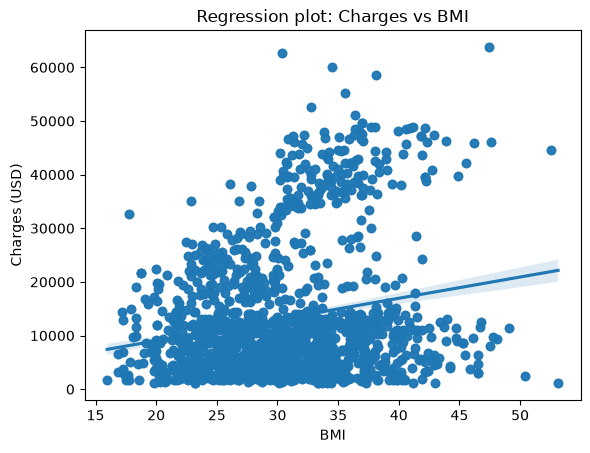

In [10]:
# Regression plot of charges against bmi.
# charges is the response (y) and bmi the predictor (x).
sns.regplot(x='bmi', y='charges', data=df)
plt.xlabel('BMI')
plt.ylabel('Charges (USD)')
plt.title('Regression plot: Charges vs BMI')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
sns.regplot(x="bmi", y="charges", data=df, line_kws={"color": "red"})
plt.ylim(0,)
```
</details>


Implement the box plot for `charges` with respect to `smoker`.


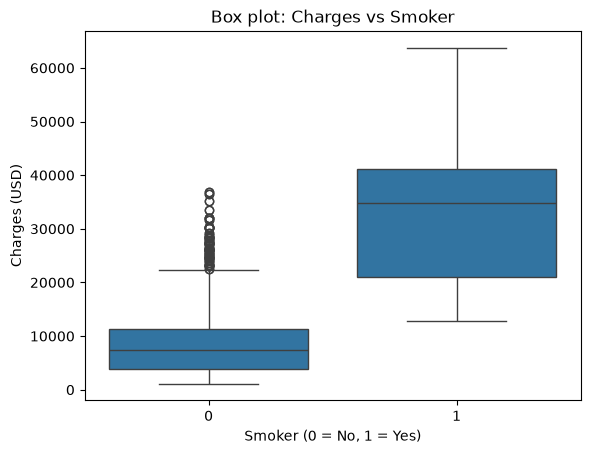

In [11]:
# Box plot of charges for each smoker category (0 = non-smoker, 1 = smoker)
sns.boxplot(x='smoker', y='charges', data=df)
plt.xlabel('Smoker (0 = No, 1 = Yes)')
plt.ylabel('Charges (USD)')
plt.title('Box plot: Charges vs Smoker')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
sns.boxplot(x="smoker", y="charges", data=df)
```
</details>


Print the correlation matrix for the dataset.


In [12]:
# Correlation matrix for the dataset
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix)

print()
print("Correlation of every attribute with charges (sorted):")
print(corr_matrix['charges'].sort_values(ascending=False))

                     age    gender       bmi  no_of_children    smoker  \
age             1.000000 -0.026046  0.113048        0.037574 -0.023286   
gender         -0.026046  1.000000  0.042924        0.016020  0.082326   
bmi             0.113048  0.042924  1.000000       -0.001492  0.011489   
no_of_children  0.037574  0.016020 -0.001492        1.000000  0.006362   
smoker         -0.023286  0.082326  0.011489        0.006362  1.000000   
region         -0.007167  0.022213  0.271119       -0.025717  0.054077   
charges         0.298624  0.062837  0.199846        0.066442  0.788783   

                  region   charges  
age            -0.007167  0.298624  
gender          0.022213  0.062837  
bmi             0.271119  0.199846  
no_of_children -0.025717  0.066442  
smoker          0.054077  0.788783  
region          1.000000  0.054058  
charges         0.054058  1.000000  

Correlation of every attribute with charges (sorted):
charges           1.000000
smoker            0.788783
ag

<details>
    <summary>Click here for Solution</summary>

```python
print(df.corr())
```
</details>


### EDA summary: which attributes most affect `charges`?

From the regression plot, the box plot and the correlation matrix above:

| Attribute | Correlation with `charges` | Reading |
|---|---|---|
| `smoker` | **0.789** | by far the strongest driver |
| `age` | 0.299 | moderate positive effect |
| `bmi` | 0.200 | weak-to-moderate positive effect |
| `no_of_children` | 0.066 | almost negligible |
| `gender` | 0.063 | almost negligible |
| `region` | 0.054 | almost negligible |

The box plot makes the `smoker` effect obvious: non-smokers are clustered at
low charges (mean ≈ 8,418 USD) while smokers sit far higher
(mean ≈ 32,223 USD) with a much wider spread.
So `smoker`, then `age` and `bmi`, are the attributes that most affect `charges`.

# Task 4 : Model Development

Fit a linear regression model that may be used to predict the `charges` value, just by using the `smoker` attribute of the dataset. Print the $ R^2 $ score of this model.


In [13]:
# Single-variable linear regression: predict charges using smoker only
lre = LinearRegression()

X_single = df[['smoker']]
y = df['charges']

lre.fit(X_single, y)
r2_single = lre.score(X_single, y)

print("R^2 score (smoker only):", r2_single)

R^2 score (smoker only): 0.6221791733924185


<details>
    <summary>Click here for Solution</summary>

```python
X = df[['smoker']]
Y = df['charges']
lm = LinearRegression()
lm.fit(X,Y)
print(lm.score(X, Y))
```
</details>


Fit a linear regression model that may be used to predict the `charges` value, just by using all other attributes of the dataset. Print the $ R^2 $ score of this model. You should see an improvement in the performance.


In [14]:
# Multi-variable linear regression: predict charges using ALL other attributes
# X = every column except the target 'charges'
X = df.drop(columns=['charges'])
y = df['charges']

lre.fit(X, y)
r2_multi = lre.score(X, y)

print("R^2 score (all attributes):", r2_multi)
print("Improvement over the smoker-only model:", round(r2_multi - r2_single, 4))

R^2 score (all attributes): 0.7504083820289634
Improvement over the smoker-only model: 0.1282


<details>
    <summary>Click here for Solution</summary>

```python
# definition of Y and lm remain same as used in last cell. 
Z = df[["age", "gender", "bmi", "no_of_children", "smoker", "region"]]
lm.fit(Z,Y)
print(lm.score(Z, Y))
```
</details>


Create a training pipeline that uses `StandardScaler()`, `PolynomialFeatures()` and `LinearRegression()` to create a model that can predict the `charges` value using all the other attributes of the dataset. There should be even further improvement in the performance.


In [15]:
# Polynomial (degree 2) pipeline: StandardScaler -> PolynomialFeatures -> LinearRegression
Input = [
    ('scaler', StandardScaler()),
    ('polynomial', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression()),
]

pipe = Pipeline(Input)

X = X.astype(float)          # all features are numeric, ensure a consistent dtype
pipe.fit(X, y)

y_pred_poly = pipe.predict(X)
r2_poly = r2_score(y, y_pred_poly)

print("R^2 score (degree-2 polynomial pipeline):", r2_poly)
print("Improvement over the linear model:", round(r2_poly - r2_multi, 4))

R^2 score (degree-2 polynomial pipeline): 0.8452576213500093
Improvement over the linear model: 0.0948


# Task 5 : Model Refinement

Split the data into training and testing subsets, assuming that 20% of the data will be reserved for testing.


In [16]:
# Split the data into training and testing subsets.
# 20% of the data is reserved for testing.
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4
)

print("Training set:", x_train.shape, " Testing set:", x_test.shape)

Training set: (2217, 6)  Testing set: (555, 6)


<details>
    <summary>Click here for Solution</summary>

```python
# Z and Y hold same values as in previous cells
x_train, x_test, y_train, y_test = train_test_split(Z, Y, test_size=0.2, random_state=1)
```
</details>


Initialize a Ridge regressor that used hyperparameter $ \alpha = 0.1 $. Fit the model using training data data subset. Print the $ R^2 $ score for the testing data.


In [17]:
# Ridge regression with the requested hyperparameter alpha = 0.1
ridge1 = Ridge(alpha=0.1)
ridge1.fit(x_train, y_train)

r2_ridge_test = ridge1.score(x_test, y_test)
print("R^2 score on the testing data (Ridge, alpha=0.1):", r2_ridge_test)

R^2 score on the testing data (Ridge, alpha=0.1): 0.7379233609510292


<details>
    <summary>Click here for Solution</summary>

```python
# x_train, x_test, y_train, y_test hold same values as in previous cells
RidgeModel=Ridge(alpha=0.1)
RidgeModel.fit(x_train, y_train)
yhat = RidgeModel.predict(x_test)
print(r2_score(y_test,yhat))
```
</details>


Apply polynomial transformation to the training parameters with degree=2. Use this transformed feature set to fit the same regression model, as above, using the training subset. Print the $ R^2 $ score for the testing subset.


In [18]:
# Apply a degree-2 polynomial transformation, then fit the same Ridge model
pr = PolynomialFeatures(degree=2, include_bias=False)

# Fit the transformer on the TRAINING data only, then use it to transform
# both the training and the testing subsets (avoids data leakage).
x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.transform(x_test)

print("Number of polynomial features:", x_train_pr.shape[1])

ridge1.fit(x_train_pr, y_train)

r2_ridge_pr = ridge1.score(x_test_pr, y_test)
print("R^2 score on the testing data (Ridge + degree-2 polynomial):", r2_ridge_pr)
print("Improvement over plain Ridge:", round(r2_ridge_pr - r2_ridge_test, 4))

Number of polynomial features: 27
R^2 score on the testing data (Ridge + degree-2 polynomial): 0.8542590258249214
Improvement over plain Ridge: 0.1163


<details>
    <summary>Click here for Solution</summary>

```python
# x_train, x_test, y_train, y_test hold same values as in previous cells
pr = PolynomialFeatures(degree=2)
x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.fit_transform(x_test)
RidgeModel.fit(x_train_pr, y_train)
y_hat = RidgeModel.predict(x_test_pr)
print(r2_score(y_test,y_hat))
```
</details>


### Summary of the models

| Model | Features | R² |
|---|---|---|
| Linear Regression | `smoker` only | 0.6222 |
| Linear Regression | all attributes | 0.7504 |
| Pipeline: StandardScaler + PolynomialFeatures(2) + LinearRegression | all attributes | 0.8453 |
| Ridge (alpha = 0.1) | all attributes, 80/20 split | 0.7379 (test) |
| Ridge (alpha = 0.1) | all attributes + degree-2 polynomial, 80/20 split | 0.8543 (test) |

**Conclusions**

* Adding attributes clearly improves on the single-variable model.
* Non-linear (degree-2 polynomial) terms capture the interaction between
  `smoker`/`age`/`bmi` and lift R² well above the plain linear model.
* The Ridge model with the polynomial feature set scores 0.854 on unseen test
  data, and it stays stable across a wide range of alpha values, because the
  L2 penalty controls the extra variance introduced by the polynomial terms.

# Congratulations! You have completed this project


## Authors


[Abhishek Gagneja](https://www.coursera.org/instructor/~129186572)

[Vicky Kuo](https://author.skills.network/instructors/vicky_kuo)


## Change Log


|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-09-16|0.1|Abhishek Gagneja|Initial Version Created|
|2023-09-19|0.2|Vicky Kuo|Reviewed and Revised|


<h3> Copyright © 2023 IBM Corporation. All rights reserved. </h3>
